In [ ]:
# Example: Hours Studied (X) and Exam Scores (Y)
hours_studied = [2, 4, 6, 8, 10]
exam_scores = [50, 60, 70, 80, 90]

# Step 1: Calculate the mean of both lists
mean_X = sum(hours_studied) / len(hours_studied)
mean_Y = sum(exam_scores) / len(exam_scores)

# Step 2: Calculate the differences from the mean for each data point
diff_X = [x - mean_X for x in hours_studied]
diff_Y = [y - mean_Y for y in exam_scores]

# Step 3: Multiply the differences for corresponding X and Y values
products = [diff_X[i] * diff_Y[i] for i in range(len(hours_studied))]

# Step 4: Sum the products
sum_products = sum(products)

# Step 5: Divide by the number of data points to get the covariance
covariance = sum_products / len(hours_studied)

# Output the result AP24110011070
print(f"Covariance between hours studied and exam scores: {covariance}")

Covariance between hours studied and exam scores: 40.0


Covariance Matrix:
 [[ 10.  50.]
 [ 50. 250.]]


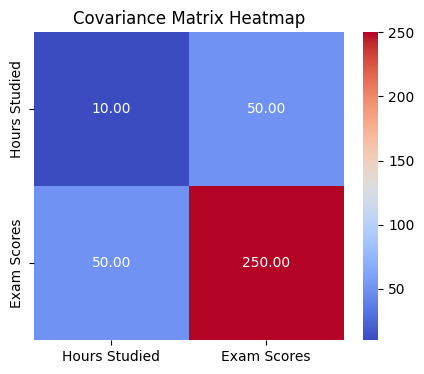

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data: Hours studied (X) and Exam scores (Y) AP24110010015
hours_studied = [2, 4, 6, 8, 10]
exam_scores = [50, 60, 70, 80, 90]

# Stack the data into a 2D array (each row is a data point, each column is a variable)
data = np.array([hours_studied, exam_scores])

# Calculate the covariance matrix using NumPy's cov function
cov_matrix = np.cov(data)

# Print the covariance matrix
print("Covariance Matrix:\n", cov_matrix)

# Plotting the covariance matrix as a heatmap
plt.figure(figsize=(5,4))
sns.heatmap(cov_matrix, annot=True, fmt=".2f", cmap="coolwarm", xticklabels=["Hours Studied", "Exam Scores"], yticklabels=["Hours Studied", "Exam Scores"])
plt.title("Covariance Matrix Heatmap")
plt.show()

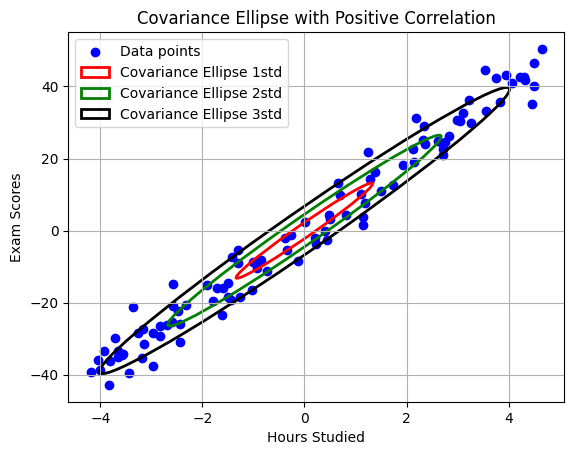

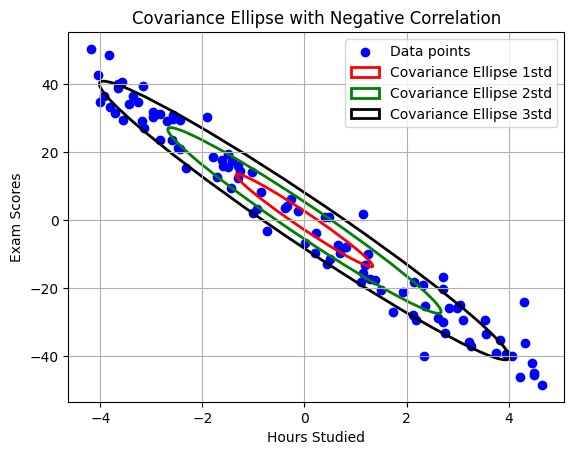

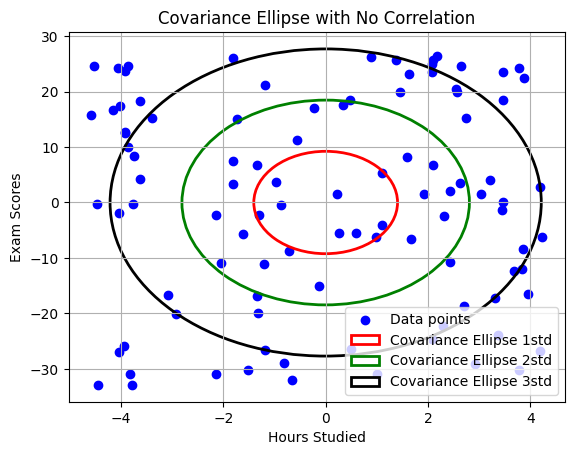

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

def plot_covariance_ellipse(hours_studied, exam_scores, title):
    mean_X = np.mean(hours_studied)
    mean_Y = np.mean(exam_scores)
    hours_studied, exam_scores=hours_studied-mean_X, exam_scores-mean_Y
    # Stack the data and calculate the covariance matrix
    data = np.vstack((hours_studied, exam_scores))
    cov_matrix = np.cov(data, rowvar=True)

    # Means of hours_studied and exam_scores


    # Eigenvalues and eigenvectors of the covariance matrix
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

    # Compute angle for the ellipse (convert from radians to degrees)
    angle = np.arctan2(*eigenvectors[:, 0][::-1]) * 180 / np.pi

    # Width and height of the ellipse (1 standard deviations in each direction)
    width, height = np.sqrt(eigenvalues)

    # Plot data points
    plt.scatter(hours_studied, exam_scores, color='blue', label='Data points')

    # Plot the covariance ellipse centered at the mean of the data
    plt.gca().add_patch(Ellipse((0,0), width, height, angle=angle, edgecolor='red', facecolor='none', lw=2, label='Covariance Ellipse 1std'))
    plt.gca().add_patch(Ellipse((0,0), 2*width,2* height, angle=angle, edgecolor='green', facecolor='none', lw=2, label='Covariance Ellipse 2std'))
    plt.gca().add_patch(Ellipse((0,0), 3*width,3* height, angle=angle, edgecolor='black', facecolor='none', lw=2, label='Covariance Ellipse 3std'))

    # Add labels and title
    plt.title(title)
    plt.xlabel('Hours Studied')
    plt.ylabel('Exam Scores')
    plt.grid(True)

    # Add legend
    plt.legend()

    # Adjust axis limits for better visibility (based on ellipse size and data)
    x_padding = width / 2
    y_padding = height / 2

    #plt.xlim(hours_studied-mean_X , hours_studied+mean_X )
    #plt.ylim(exam_scores-mean_Y , exam_scores+mean_Y )

    # Show plot
    plt.show()

# Positive correlation data (as previously)
np.random.seed(42)
hours_studied_pos = np.random.uniform(1, 10, 100)
exam_scores_pos = 10 * hours_studied_pos + np.random.normal(0, 5, size=hours_studied_pos.shape)
plot_covariance_ellipse(hours_studied_pos, exam_scores_pos, 'Covariance Ellipse with Positive Correlation')

# Negative correlation data
exam_scores_neg = -10 * hours_studied_pos + np.random.normal(0, 5, size=hours_studied_pos.shape) + 100  # Shift to ensure positive values
plot_covariance_ellipse(hours_studied_pos, exam_scores_neg, 'Covariance Ellipse with Negative Correlation')


# No correlation data
hours_studied_no = np.random.uniform(1, 10, 100)
exam_scores_no = np.random.uniform(40, 100, 100)  # Completely random, independent of hours_studied
plot_covariance_ellipse(hours_studied_no, exam_scores_no, 'Covariance Ellipse with No Correlation')

In [ ]:
# Calculate the standard deviations (square root of diagonal elements)
std_devs = np.sqrt(np.diag(cov_matrix))

# Outer product of standard deviations to form the denominator matrix
denominator_matrix = np.outer(std_devs, std_devs)

# Calculate correlation matrix
correlation_matrix = cov_matrix / denominator_matrix

# Set the diagonal elements to 1 (just to be sure, though they should already be 1)
np.fill_diagonal(correlation_matrix, 1)

print("Covariance Matrix:\n", cov_matrix)
print("Correlation Matrix:\n", correlation_matrix)

Covariance Matrix:
 [[ 10.  50.]
 [ 50. 250.]]
Correlation Matrix:
 [[1. 1.]
 [1. 1.]]


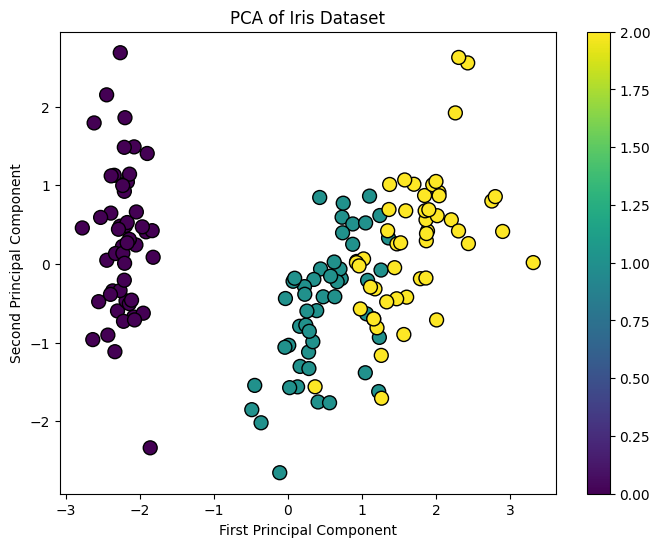

In [ ]:
# Import the required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# Load the Iris dataset
iris = load_iris()
X = iris.data  # Features
y = iris.target  # Labels

# Standardize the features (important for PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA to reduce to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the two principal components
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', edgecolor='k', s=100)
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('PCA of Iris Dataset')
plt.colorbar()
plt.show()

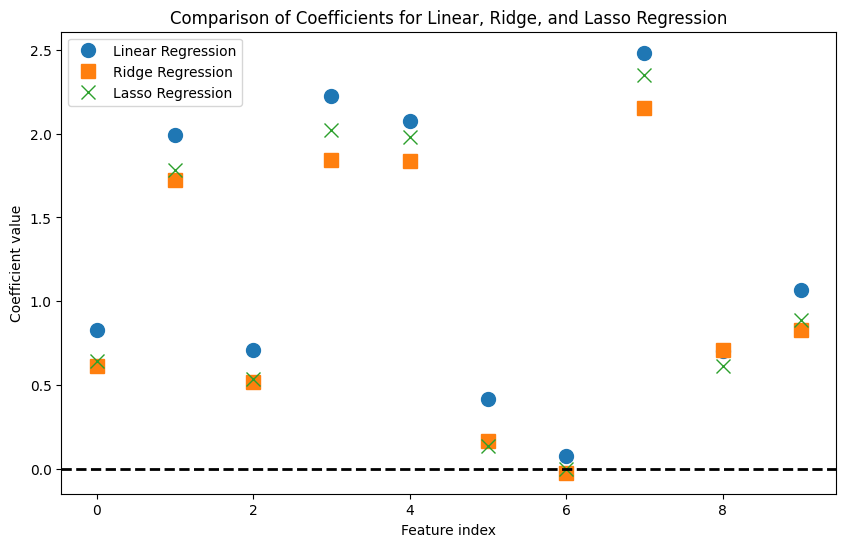

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler

# Create a synthetic dataset with multicollinearity (highly correlated features)
# We'll use make_regression to generate data with 1000 samples, 20 features, and a small noise level
# 'effective_rank' creates correlated features
X, y = make_regression(n_samples=1000, n_features=10, noise=0.3, random_state=42, effective_rank=5)

# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the data (important for regularization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- Ordinary Least Squares (Linear Regression) ---
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

# --- Ridge Regression (L2 Regularization) with a large alpha ---
ridge_reg = Ridge(alpha=100)  # Use a large alpha to shrink coefficients more
ridge_reg.fit(X_train_scaled, y_train)

# --- Lasso Regression (L1 Regularization) with a moderate alpha ---
lasso_reg = Lasso(alpha=0.1)  # Lasso tends to set some coefficients to zero
lasso_reg.fit(X_train_scaled, y_train)

# Plot the coefficients to show how Ridge and Lasso affect them compared to Linear Regression
plt.figure(figsize=(10,6))

# Plot the coefficients from Linear Regression (no regularization)
plt.plot(lin_reg.coef_, 'o', label='Linear Regression', markersize=10)

# Plot the coefficients from Ridge Regression (L2 regularization)
plt.plot(ridge_reg.coef_, 's', label='Ridge Regression', markersize=10)

# Plot the coefficients from Lasso Regression (L1 regularization)
plt.plot(lasso_reg.coef_, 'x', label='Lasso Regression', markersize=10)

# Add a horizontal line at y=0 to make it easier to see where coefficients are being shrunk toward zero
plt.axhline(0, color='black', linestyle='--', lw=2)

# Add titles and labels
plt.title('Comparison of Coefficients for Linear, Ridge, and Lasso Regression')
plt.xlabel('Feature index')
plt.ylabel('Coefficient value')

# Add a legend to distinguish between the models
plt.legend()

# Show the plot
plt.show()